In [1]:
# Библиотека для работы с таблицами
import pandas as pd

# Библиотека для числовых вычислений
import numpy as np

# Библиотеки для визуализации данных
import matplotlib.pyplot as plt
import seaborn as sns

# Настройки отображения графиков
sns.set_theme(style="whitegrid")

# Показывать все столбцы таблицы
pd.set_option("display.max_columns", None)

In [2]:
#from google.colab import files

## Загружаем CSV-файл с компьютера
#uploaded = files.upload()

# Считываем датасет
df = pd.read_csv("satellite_linear_regression_600.csv")

# Показываем первые 5 строк
df.head()

,current,voltage,power,mode,temperature
0,2.222,27.758,61.680,active,48.25
1,1.075,27.706,29.784,normal,28.04
2,1.197,27.567,33.001,normal,29.93
3,0.562,27.618,15.522,standby,20.59
4,1.287,27.966,35.991,normal,29.80


In [3]:
# Размер датасета: количество строк и столбцов
print("Размер датасета:", df.shape)

print("Количество строк:", df.shape[0])
print("Количество столбцов:", df.shape[1])

# Названия всех столбцов
print("\nНазвания столбцов:")
print(df.columns.tolist())

# Последние 5 строк
display(df.tail())

Размер датасета: (600, 5)
Количество строк: 600
Количество столбцов: 5

Названия столбцов:
['current', 'voltage', 'power', 'mode', 'temperature']


,current,voltage,power,mode,temperature
595,0.218,28.106,6.122,standby,17.82
596,1.499,28.236,42.318,normal,32.55
597,0.532,27.833,14.817,standby,21.44
598,1.872,28.109,52.606,active,42.12
599,2.409,27.378,65.956,active,46.66


В нашем датасете 600 наблюдений и 5 признаков, включая целевую переменную temperature.

In [4]:
# Информация о датасете
df.info()

# Отдельно выводим тип каждого столбца
print("\nТипы данных:")
print(df.dtypes)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   current      600 non-null    float64
 1   voltage      600 non-null    float64
 2   power        600 non-null    float64
 3   mode         600 non-null    object 
 4   temperature  600 non-null    float64
dtypes: float64(4), object(1)
memory usage: 23.6+ KB

Типы данных:
current        float64
voltage        float64
power          float64
mode            object
temperature    float64
dtype: object


Здесь важно обратить внимание: current, voltage, power и temperature — числовые данные, а mode — категориальные. Перед использованием mode в линейной регрессии его необходимо закодировать.

In [5]:
# Количество пропусков в каждом столбце
print("Количество пропущенных значений:")
print(df.isnull().sum())

# Процент пропущенных значений
missing_percent = df.isnull().mean() * 100

print("\nПроцент пропусков:")
print(missing_percent.round(2))

# Общее количество пропусков
print("\nВсего пропущенных значений:")
print(df.isnull().sum().sum())

Количество пропущенных значений:
current        0
voltage        0
power          0
mode           0
temperature    0
dtype: int64

Процент пропусков:
current        0.0
voltage        0.0
power          0.0
mode           0.0
temperature    0.0
dtype: float64

Всего пропущенных значений:
0


In [6]:
# Количество полностью одинаковых строк
print("Количество дубликатов:", df.duplicated().sum())

Количество дубликатов: 0


In [7]:
# Описательная статистика числовых столбцов
display(df.describe().round(2))

# Статистика по всем столбцам, включая mode
display(df.describe(include="all"))

,current,voltage,power,temperature
count,600.00,600.00,600.00,600.00
mean,1.37,27.61,37.57,33.74
std,0.63,0.41,17.26,9.51
min,0.20,26.40,5.52,15.03
25%,0.76,27.32,21.35,24.87
50%,1.37,27.60,37.91,33.49
75%,1.94,27.90,52.80,42.52
max,2.64,28.60,71.95,57.66


,current,voltage,power,mode,temperature
count,600.000000,600.000000,600.000000,600,600.000000
unique,NaN,NaN,NaN,3,NaN
top,NaN,NaN,NaN,active,NaN
freq,NaN,NaN,NaN,200,NaN
mean,1.365028,27.608052,37.568012,NaN,33.742850
std,0.633724,0.411346,17.256839,NaN,9.507706
min,0.200000,26.400000,5.524000,NaN,15.030000
25%,0.763000,27.323750,21.345250,NaN,24.867500
50%,1.368500,27.596500,37.906500,NaN,33.490000
75%,1.936250,27.895250,52.802500,NaN,42.522500


count — количество значений;



mean — среднее;



std — стандартное отклонение;



min, max — минимальное и максимальное значения;



25%, 50%, 75% — квартили.

**Смотрим распределение режимов работы спутника**

mode
active     200
normal     200
standby    200
Name: count, dtype: int64


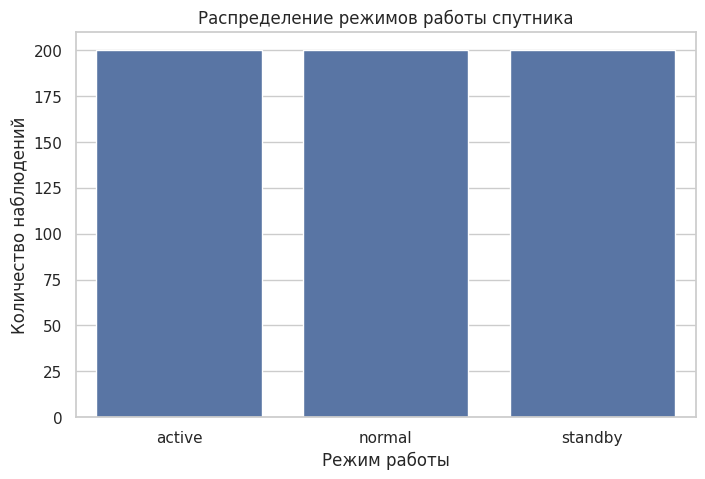

In [8]:
# Количество наблюдений каждого режима
print(df["mode"].value_counts())

# Строим столбчатую диаграмму
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="mode",
    order=df["mode"].value_counts().index
)

plt.title("Распределение режимов работы спутника")
plt.xlabel("Режим работы")
plt.ylabel("Количество наблюдений")

plt.show()

**Изучаем распределение числовых признаков**

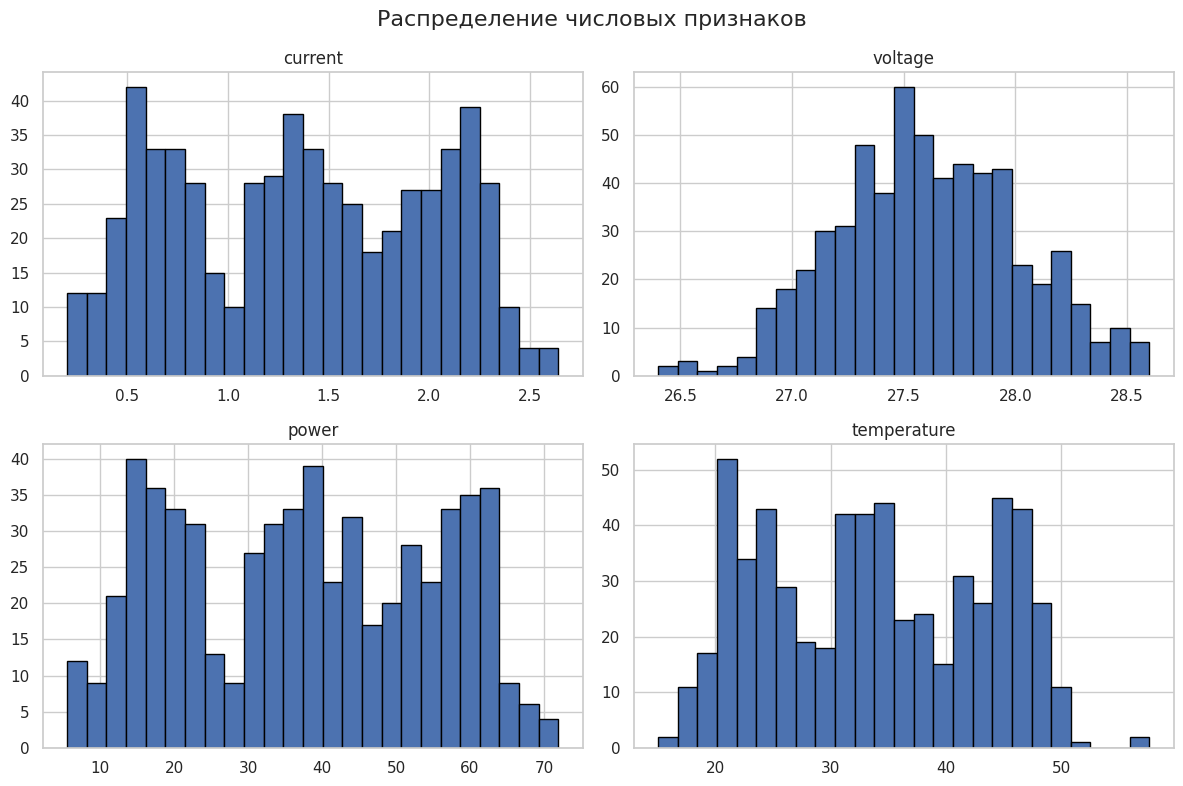

In [9]:
# Выбираем только числовые столбцы
numeric_columns = df.select_dtypes(include=np.number).columns

# Строим гистограммы
df[numeric_columns].hist(
    figsize=(12, 8),
    bins=25,
    edgecolor="black"
)

plt.suptitle("Распределение числовых признаков", fontsize=16)
plt.tight_layout()
plt.show()

Гистограммы позволяют увидеть, какие значения встречаются чаще, насколько большой разброс у признаков и есть ли необычные значения.

**Подробно изучаем распределение температуры**

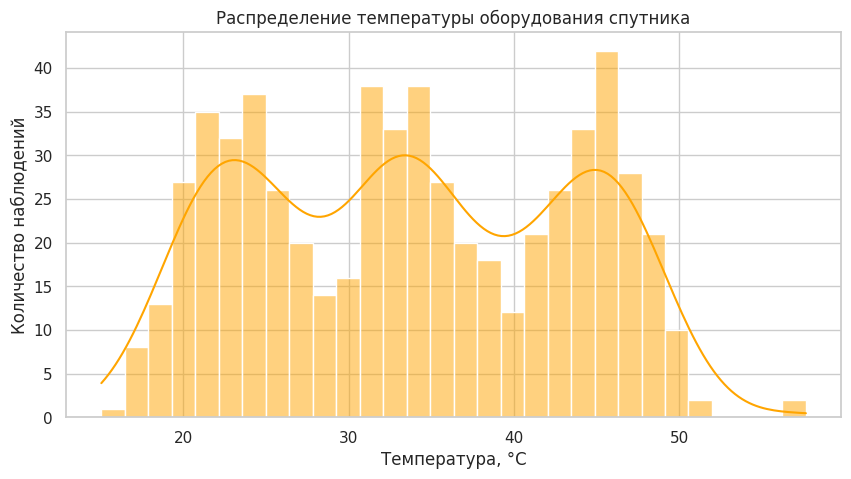

Средняя температура: 33.74
Медианная температура: 33.49
Минимальная температура: 15.03
Максимальная температура: 57.66


In [10]:
plt.figure(figsize=(10, 5))

# Гистограмма температуры с кривой плотности
sns.histplot(
    data=df,
    x="temperature",
    bins=30,
    kde=True,
    color="orange"
)

plt.title("Распределение температуры оборудования спутника")
plt.xlabel("Температура, °C")
plt.ylabel("Количество наблюдений")

plt.show()

# Основные характеристики температуры
print("Средняя температура:", round(df["temperature"].mean(), 2))
print("Медианная температура:", round(df["temperature"].median(), 2))
print("Минимальная температура:", df["temperature"].min())
print("Максимальная температура:", df["temperature"].max())

**Сравниваем температуру в разных режимах работы**

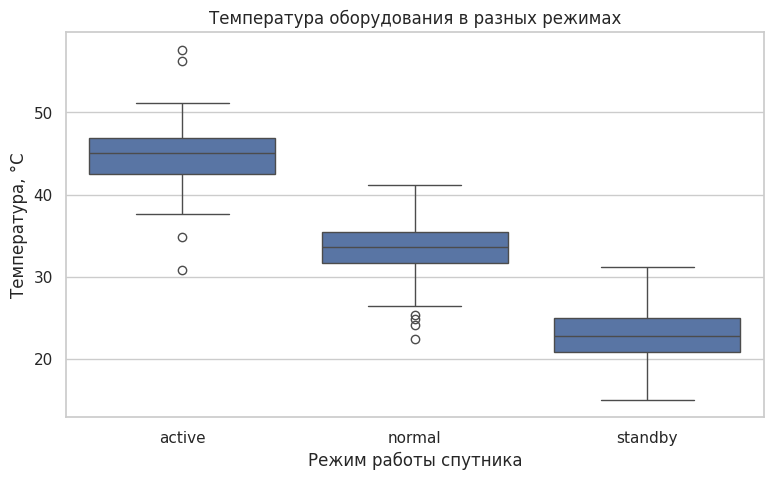

,count,mean,min,max,std
mode,,,,,
active,200,44.86,30.77,57.66,3.33
normal,200,33.45,22.34,41.13,3.17
standby,200,22.92,15.03,31.14,2.99


In [11]:
plt.figure(figsize=(9, 5))

# Boxplot показывает медиану, квартили и возможные выбросы
sns.boxplot(
    data=df,
    x="mode",
    y="temperature"
)

plt.title("Температура оборудования в разных режимах")
plt.xlabel("Режим работы спутника")
plt.ylabel("Температура, °C")

plt.show()

# Статистика температуры по режимам
display(
    df.groupby("mode")["temperature"]
    .agg(["count", "mean", "min", "max", "std"])
    .round(2)
)

Этот график поможет определить, отличается ли температура между режимами standby, normal и active.

**Строим диаграмму рассеяния — ток и температура**

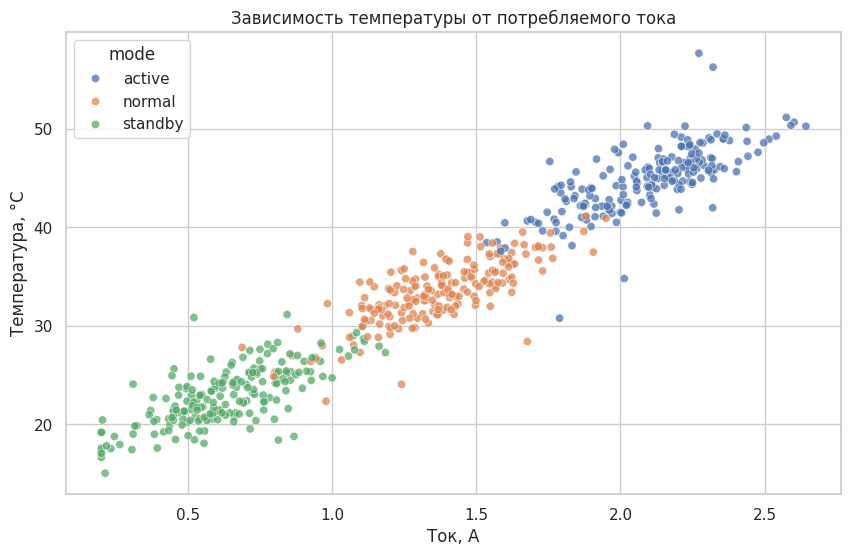

In [12]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="current",
    y="temperature",
    hue="mode",
    alpha=0.75
)

plt.title("Зависимость температуры от потребляемого тока")
plt.xlabel("Ток, А")
plt.ylabel("Температура, °C")

plt.show()

Здесь каждая точка соответствует одному измерению. Цвет показывает режим работы спутника.
Студенты смогут увидеть, существует ли визуальная зависимость между током и температурой, а также как на неё влияет режим работы.

**Проверяем корреляцию признаков**

,current,voltage,power,temperature
current,1.00,-0.45,1.00,0.97
voltage,-0.45,1.00,-0.43,-0.51
power,1.00,-0.43,1.00,0.97
temperature,0.97,-0.51,0.97,1.00


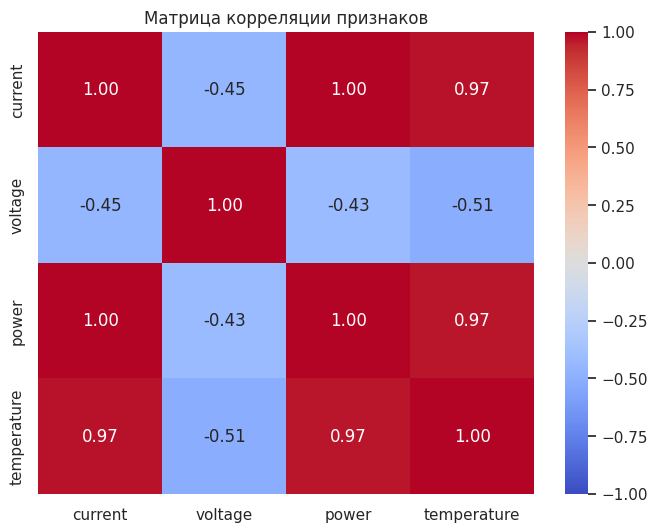

In [13]:
# Вычисляем корреляцию только числовых столбцов
correlation = df.select_dtypes(include=np.number).corr()

# Выводим таблицу корреляций
display(correlation.round(2))

# Строим тепловую карту
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Матрица корреляции признаков")
plt.show()

Корреляция показывает направление и силу линейной связи между двумя числовыми переменными. Значение около +1 соответствует сильной положительной связи, около −1 — сильной отрицательной, а около 0 — слабой линейной связи.
В нашем случае особое внимание стоит обратить на корреляцию current и temperature, а также current и power, поскольку мощность рассчитывается через ток и напряжение.

**Выбираем входной признак X и целевую переменную y**

In [14]:
# X — входные данные (ток потребления)
# Используем двойные скобки, чтобы получить таблицу DataFrame
X = df[["current"]]

# y — целевая переменная (температура)
y = df["temperature"]

# Проверяем размеры
print("Размер X:", X.shape)
print("Размер y:", y.shape)

# Посмотрим на первые значения
display(X.head())
display(y.head())

Размер X: (600, 1)
Размер y: (600,)


,current
0,2.222
1,1.075
2,1.197
3,0.562
4,1.287


,temperature
0,48.25
1,28.04
2,29.93
3,20.59
4,29.80


Обратите внимание: X содержит только один признак — ток, хотя в исходном датасете есть и другие параметры. Это позволит построить простую линейную регрессию и визуализировать её в виде прямой линии.

**Делим данные на обучающую и тестовую выборки**

In [15]:
from sklearn.model_selection import train_test_split

# Разделяем данные на Train (80%) и Test (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Обучающих наблюдений:", len(X_train))
print("Тестовых наблюдений:", len(X_test))

Обучающих наблюдений: 480
Тестовых наблюдений: 120


**Создаём и обучаем модель LinearRegression**

In [16]:
from sklearn.linear_model import LinearRegression

# Создаём модель линейной регрессии
model = LinearRegression()

# Обучаем модель на обучающей выборке
model.fit(X_train, y_train)

print("Модель успешно обучена!")

Модель успешно обучена!


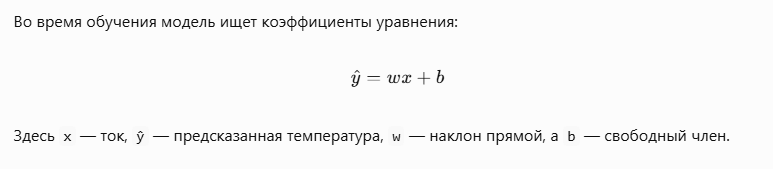

**Смотрим, какую формулу нашла модель**

In [17]:
# Получаем коэффициенты обученной модели
w = model.coef_[0]
b = model.intercept_

print(f"Коэффициент наклона (w): {w:.4f}")
print(f"Свободный член (b): {b:.4f}")

# Выводим найденное уравнение
print(f"\nУравнение модели:")
print(f"Temperature = {w:.4f} × Current + ({b:.4f})")

Коэффициент наклона (w): 14.5088
Свободный член (b): 13.9397

Уравнение модели:
Temperature = 14.5088 × Current + (13.9397)


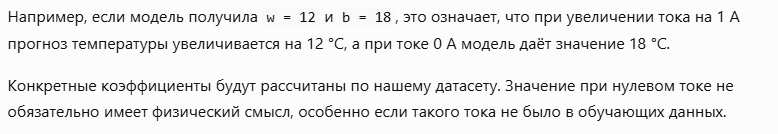

**Строим прямую линейной регрессии**

Теперь посмотрим, как обученная модель описывает реальные измерения.

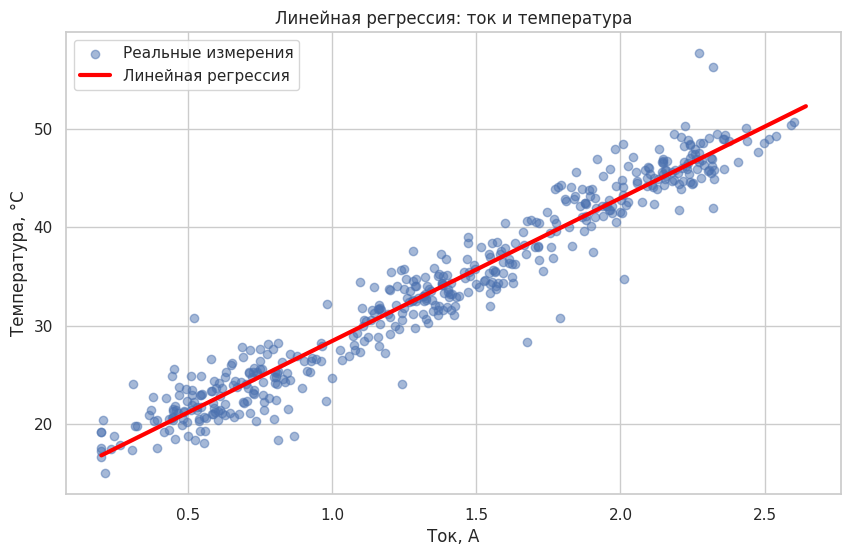

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# Создаём 100 значений тока от минимального до максимального
current_range = np.linspace(
    X["current"].min(),
    X["current"].max(),
    100
)

# Преобразуем значения в DataFrame
current_df = pd.DataFrame({
    "current": current_range
})

# Предсказываем температуру для каждого значения тока
temperature_pred = model.predict(current_df)

plt.figure(figsize=(10, 6))

# Реальные измерения из обучающей выборки
plt.scatter(
    X_train["current"],
    y_train,
    alpha=0.5,
    label="Реальные измерения"
)

# Линия обученной модели
plt.plot(
    current_range,
    temperature_pred,
    color="red",
    linewidth=3,
    label="Линейная регрессия"
)

plt.title("Линейная регрессия: ток и температура")
plt.xlabel("Ток, А")
plt.ylabel("Температура, °C")
plt.legend()
plt.grid(True)

plt.show()

На графике точки показывают реальные измерения, а красная линия — предсказания модели. Она не обязана проходить через каждую точку: алгоритм подбирает прямую, минимизирующую сумму квадратов ошибок.

**Получаем предсказания на тестовой выборке**

Теперь проверим модель на наблюдениях, которые она не использовала во время обучения.

In [19]:
# Предсказываем температуру для тестовой выборки
y_pred = model.predict(X_test)

# Создаём таблицу для сравнения
results = pd.DataFrame({
    "Current": X_test["current"].to_numpy(),
    "Real temperature": y_test.to_numpy(),
    "Predicted temperature": y_pred
})

# Вычисляем абсолютную ошибку
results["Absolute error"] = abs(
    results["Real temperature"] -
    results["Predicted temperature"]
)

# Показываем первые 10 результатов
display(results.head(10).round(2))

,Current,Real temperature,Predicted temperature,Absolute error
0,1.80,41.59,40.01,1.58
1,2.13,45.82,44.90,0.92
2,1.43,34.37,34.66,0.29
3,1.73,39.63,39.04,0.59
4,2.40,45.64,48.79,3.15
5,1.99,47.57,42.86,4.71
6,2.18,47.14,45.54,1.60
7,0.88,25.27,26.78,1.51
8,2.13,47.05,44.86,2.19
9,2.58,51.15,51.30,0.15


Мы получили таблицу, в которой можно сравнить реальную температуру и прогноз модели для каждого наблюдения.

**Визуализируем реальные и предсказанные значения**

Хорошая модель должна давать прогнозы, близкие к фактическим измерениям.

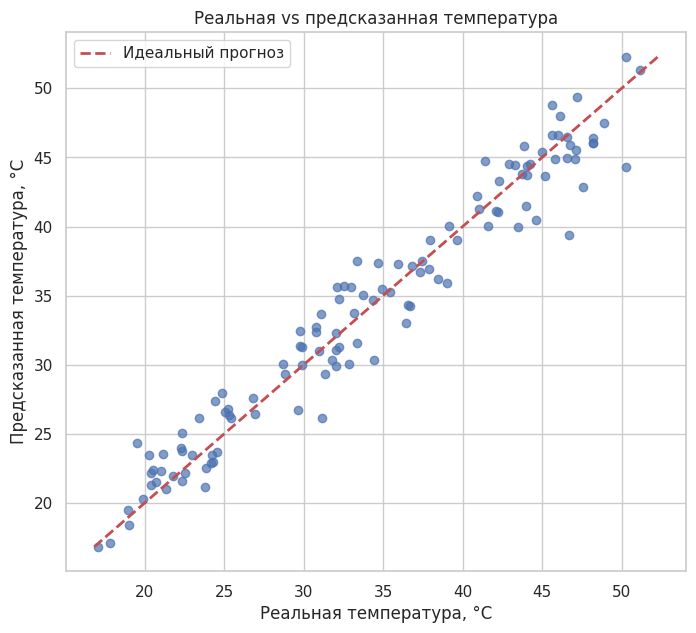

In [20]:
plt.figure(figsize=(8, 7))

# Реальные значения по оси X
# Предсказанные значения по оси Y
plt.scatter(
    y_test,
    y_pred,
    alpha=0.7
)

# Границы для линии идеального прогноза
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

# Линия идеальных предсказаний: y = x
plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--",
    linewidth=2,
    label="Идеальный прогноз"
)

plt.xlabel("Реальная температура, °C")
plt.ylabel("Предсказанная температура, °C")
plt.title("Реальная vs предсказанная температура")
plt.legend()
plt.grid(True)

plt.show()

Чем ближе точки к красной пунктирной линии, тем точнее модель предсказывает температуру. Если точки сильно разбросаны, значит модель допускает значительные ошибки.

**Вычисляем метрики качества регрессии**

Используем четыре метрики: MAE, MSE, RMSE и R².

In [21]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# MAE — средняя абсолютная ошибка
mae = mean_absolute_error(y_test, y_pred)

# MSE — средняя квадратичная ошибка
mse = mean_squared_error(y_test, y_pred)

# RMSE — корень из MSE
rmse = np.sqrt(mse)

# R² — коэффициент детерминации
r2 = r2_score(y_test, y_pred)

print("Метрики качества модели:")
print(f"MAE:  {mae:.3f} °C")
print(f"MSE:  {mse:.3f} °C²")
print(f"RMSE: {rmse:.3f} °C")
print(f"R²:   {r2:.3f}")

Метрики качества модели:
MAE:  1.673 °C
MSE:  4.517 °C²
RMSE: 2.125 °C
R²:   0.950


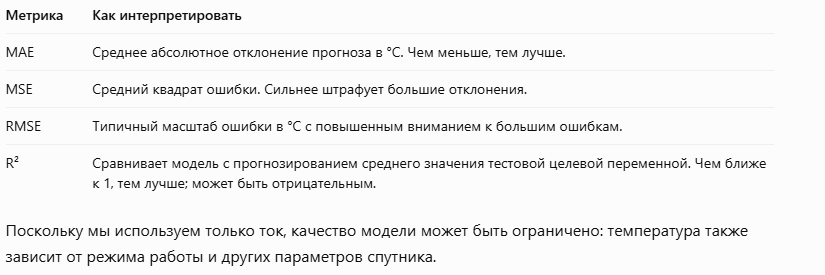

Поскольку мы используем только ток, качество модели может быть ограничено: температура также зависит от режима работы и других параметров спутника.

**Посмотрим, где модель ошибается сильнее всего**

10 самых больших ошибок модели:


,Current,Real temperature,Predicted temperature,Absolute error
104,1.76,46.67,39.40,7.27
92,2.09,50.29,44.32,5.97
72,0.84,31.14,26.19,4.95
42,0.72,19.53,24.33,4.80
5,1.99,47.57,42.86,4.71
73,1.83,44.60,40.45,4.15
39,1.13,34.45,30.35,4.10
56,1.62,33.39,37.49,4.10
69,1.50,32.08,35.66,3.58
17,1.79,43.48,39.95,3.53


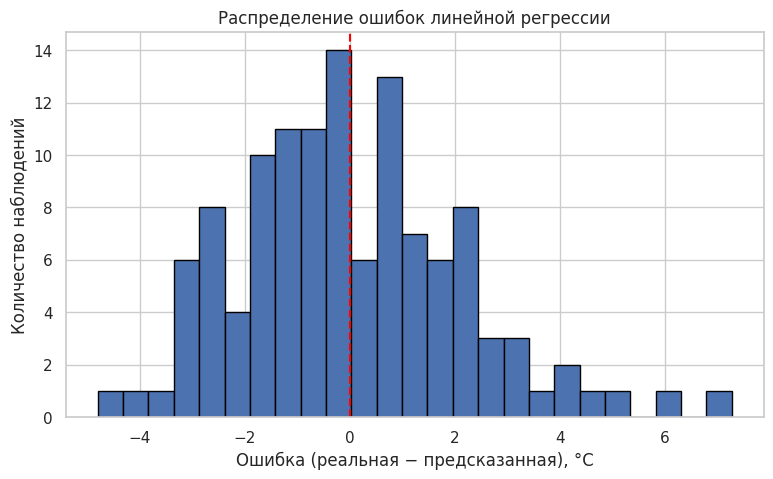

In [22]:
# Сортируем результаты по величине абсолютной ошибки
worst_predictions = results.sort_values(
    by="Absolute error",
    ascending=False
)

print("10 самых больших ошибок модели:")
display(worst_predictions.head(10).round(2))

# Гистограмма ошибок предсказания
errors = y_test.to_numpy() - y_pred

plt.figure(figsize=(9, 5))

plt.hist(
    errors,
    bins=25,
    edgecolor="black"
)

plt.axvline(0, color="red", linestyle="--")

plt.xlabel("Ошибка (реальная − предсказанная), °C")
plt.ylabel("Количество наблюдений")
plt.title("Распределение ошибок линейной регрессии")
plt.grid(True)

plt.show()

**Проверяем обученную модель на новых данных**

Самая важная часть: мы уже обучили модель, теперь можем передать ей новые значения тока и получить прогноз температуры.

In [23]:
# Новые значения тока, для которых хотим получить прогноз
new_data = pd.DataFrame({
    "current": [0.8, 1.2, 1.8, 2.3]
})

# Получаем прогнозы
new_predictions = model.predict(new_data)

# Формируем таблицу результатов
forecast = new_data.copy()
forecast["Predicted temperature"] = new_predictions

print("Прогноз температуры для новых измерений:")
display(forecast.round(2))

Прогноз температуры для новых измерений:


,current,Predicted temperature
0,0.8,25.55
1,1.2,31.35
2,1.8,40.06
3,2.3,47.31


Эти значения тока не нужно предварительно добавлять в обучающий датасет. Модель использует найденное уравнение для вычисления температуры. Однако прогнозы наиболее обоснованы в диапазоне значений тока, представленном в обучающих данных.

**Итоги обучения первой модели**

В конце практики можно вывести основные результаты в одном месте.

In [24]:
print("=" * 45)
print("ИТОГИ: ПРОСТАЯ ЛИНЕЙНАЯ РЕГРЕССИЯ")
print("=" * 45)

print(f"Входной признак: current")
print(f"Целевая переменная: temperature")
print(f"Обучающих примеров: {len(X_train)}")
print(f"Тестовых примеров: {len(X_test)}")

print(f"\nУравнение:")
print(f"Temperature = {w:.3f} × Current + ({b:.3f})")

print(f"\nКачество модели на тестовых данных:")
print(f"MAE = {mae:.3f} °C")
print(f"MSE = {mse:.3f} °C²")
print(f"RMSE = {rmse:.3f} °C")
print(f"R² = {r2:.3f}")

ИТОГИ: ПРОСТАЯ ЛИНЕЙНАЯ РЕГРЕССИЯ
Входной признак: current
Целевая переменная: temperature
Обучающих примеров: 480
Тестовых примеров: 120

Уравнение:
Temperature = 14.509 × Current + (13.940)

Качество модели на тестовых данных:
MAE = 1.673 °C
MSE = 4.517 °C²
RMSE = 2.125 °C
R² = 0.950
